<a href="https://colab.research.google.com/github/torcodex/Student-Performance-Predictor/blob/main/Student_Performance_Predictor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [129]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

df = pd.read_csv('/content/drive/MyDrive/student_performance_data - student_performance_data.csv')
df

,hours_studied,attendance,sleep_hours,previous_scores,tutoring_sessions,physical_activity,gender,parental_education,internet_access,performance_score
0,4.4,87.9,6.2,81.2,7.0,6,Male,Masters,Yes,80.1
1,9.6,51.2,6.7,87.7,6.0,1,Male,Masters,Yes,89.1
2,7.6,51.1,4.5,40.3,7.0,2,Female,High School,Yes,65.5
3,6.4,66.2,5.8,88.3,0.0,3,Female,High School,Yes,66.1
4,2.4,74.4,8.4,67.8,4.0,2,Male,Bachelors,Yes,61.3
...,...,...,...,...,...,...,...,...,...,...
1195,8.8,67.3,9.6,38.3,6.0,0,Female,Bachelors,Yes,69.7
1196,9.8,57.7,7.3,32.6,0.0,4,Male,High School,No,57.3
1197,9.7,51.3,9.4,33.7,1.0,6,Male,Bachelors,Yes,70.7
1198,7.7,82.3,5.9,88.4,2.0,4,Male,High School,Yes,83.2


In [130]:
df.isna().sum()

,0
hours_studied,0
attendance,0
sleep_hours,34
previous_scores,25
tutoring_sessions,18
physical_activity,0
gender,15
parental_education,20
internet_access,0
performance_score,0


In [131]:
df.duplicated().sum()

np.int64(0)

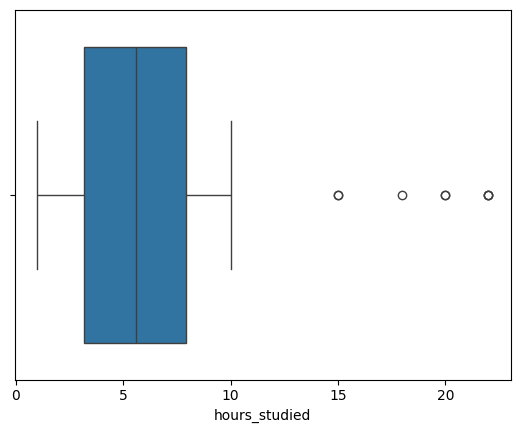

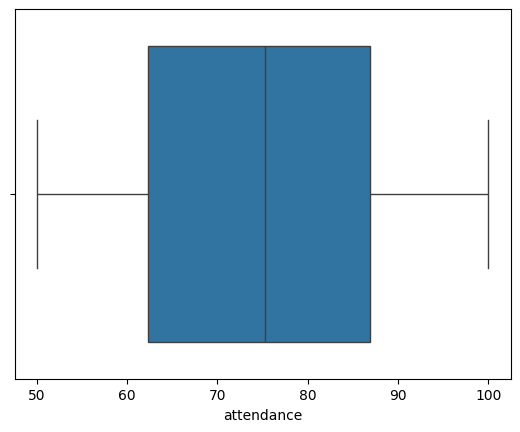

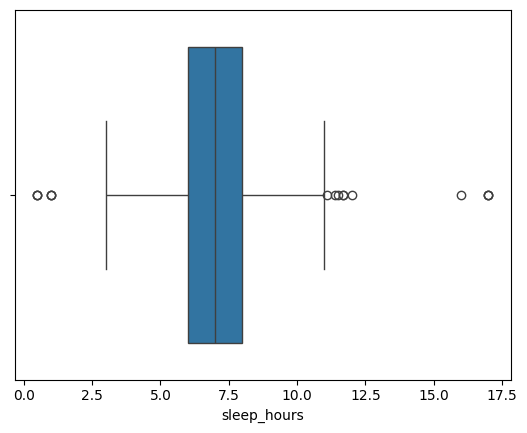

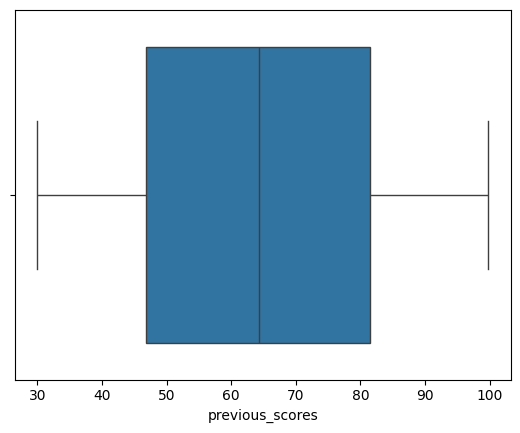

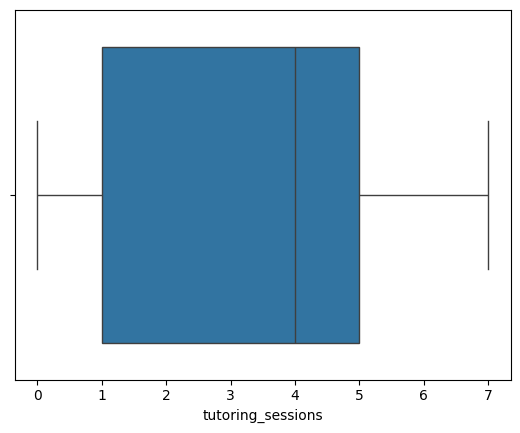

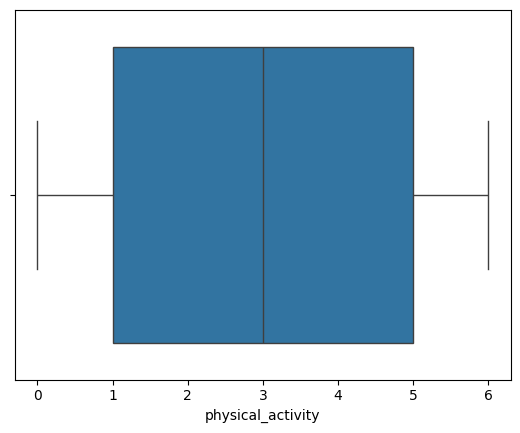

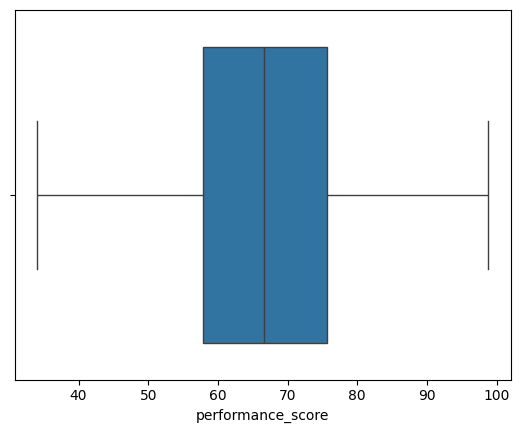

In [132]:
for col in df.select_dtypes(include='number').columns:
  sns.boxplot(data = df, x = col)
  plt.show()

In [133]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   hours_studied       1200 non-null   float64
 1   attendance          1200 non-null   float64
 2   sleep_hours         1166 non-null   float64
 3   previous_scores     1175 non-null   float64
 4   tutoring_sessions   1182 non-null   float64
 5   physical_activity   1200 non-null   int64  
 6   gender              1185 non-null   object 
 7   parental_education  1180 non-null   object 
 8   internet_access     1200 non-null   object 
 9   performance_score   1200 non-null   float64
dtypes: float64(6), int64(1), object(3)
memory usage: 93.9+ KB


In [134]:
out_col = ['hours_studied','sleep_hours']

In [135]:
for col in out_col:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)

  IQR = Q3 - Q1

  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

In [136]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1142 entries, 0 to 1199
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   hours_studied       1142 non-null   float64
 1   attendance          1142 non-null   float64
 2   sleep_hours         1142 non-null   float64
 3   previous_scores     1118 non-null   float64
 4   tutoring_sessions   1124 non-null   float64
 5   physical_activity   1142 non-null   int64  
 6   gender              1130 non-null   object 
 7   parental_education  1123 non-null   object 
 8   internet_access     1142 non-null   object 
 9   performance_score   1142 non-null   float64
dtypes: float64(6), int64(1), object(3)
memory usage: 98.1+ KB


In [137]:
df.isna().sum()

,0
hours_studied,0
attendance,0
sleep_hours,0
previous_scores,24
tutoring_sessions,18
physical_activity,0
gender,12
parental_education,19
internet_access,0
performance_score,0


In [138]:
df['previous_scores'] = df['previous_scores'].fillna(df['previous_scores'].median())

In [139]:
ob_cols = df.select_dtypes(include='object').columns
ob_cols

Index(['gender', 'parental_education', 'internet_access'], dtype='object')

In [140]:
df['parental_education'].unique()

array(['Masters', 'High School', 'Bachelors', 'PhD', nan], dtype=object)

In [141]:
df['parental_education'] = df['parental_education'].fillna(df['parental_education'].mode()[0])
df['parental_education'].unique()

array(['Masters', 'High School', 'Bachelors', 'PhD'], dtype=object)

In [142]:
df['gender'] = df['gender'].fillna(df['gender'].mode()[0])
df['gender'].unique()

array(['Male', 'Female'], dtype=object)

In [143]:
df['tutoring_sessions'] = df['tutoring_sessions'].fillna(df['tutoring_sessions'].median())

In [144]:
le = LabelEncoder()
for col in ob_cols:
  df[col] = le.fit_transform(df[col])

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1142 entries, 0 to 1199
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   hours_studied       1142 non-null   float64
 1   attendance          1142 non-null   float64
 2   sleep_hours         1142 non-null   float64
 3   previous_scores     1142 non-null   float64
 4   tutoring_sessions   1142 non-null   float64
 5   physical_activity   1142 non-null   int64  
 6   gender              1142 non-null   int64  
 7   parental_education  1142 non-null   int64  
 8   internet_access     1142 non-null   int64  
 9   performance_score   1142 non-null   float64
dtypes: float64(6), int64(4)
memory usage: 98.1 KB


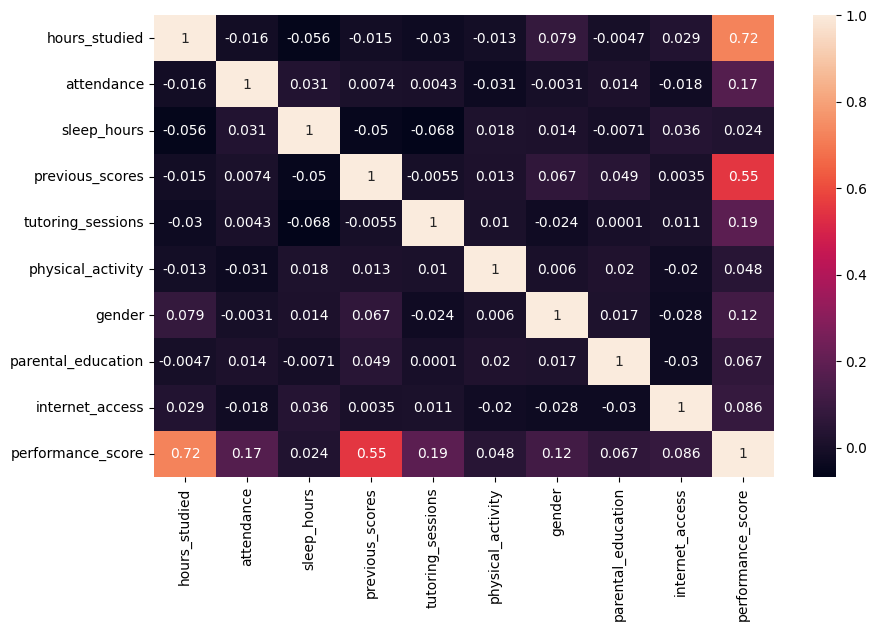

In [145]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(),annot=True)
plt.show()

In [146]:
x = df.drop('performance_score',axis=1)
y = df['performance_score']

In [185]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.3,random_state=42)

In [186]:
model = LinearRegression()

In [187]:
model.fit(x_train,y_train)

LinearRegression()

In [188]:
y_pred = model.predict(x_test)
y_pred

array([56.27949689, 44.99556014, 84.27006176, 39.03803851, 74.23263837,
       62.19487527, 90.20619067, 69.39516792, 85.79674422, 67.0949345 ,
       50.11823261, 63.73510976, 71.02593425, 70.53414976, 62.56199676,
       58.57152391, 62.20866907, 90.29496   , 80.05339479, 79.19748251,
       64.81596141, 60.18767896, 59.71258868, 71.84715502, 57.56650169,
       64.23333738, 75.25910208, 76.70363581, 55.76680439, 89.47328181,
       64.45782956, 53.78354659, 75.21394863, 71.86842952, 64.62675052,
       63.62159963, 68.41369437, 46.22921343, 79.71049315, 59.19612365,
       53.93950017, 77.88615611, 39.56156058, 66.03633393, 89.50691118,
       74.60087856, 81.49631456, 56.36113307, 60.92085795, 64.2275609 ,
       64.49932155, 78.01912626, 80.14139785, 71.17355798, 70.85631438,
       68.34495025, 59.67998479, 72.13202343, 52.82229531, 81.25321277,
       62.72386314, 90.65389898, 81.44802141, 55.55548111, 82.73981062,
       48.41671332, 60.88721419, 73.17936819, 59.49218811, 73.49

In [189]:
mean_absolute_error(y_test,y_pred)

2.629108901282079

In [190]:
root_mean_squared_error(y_test,y_pred)

3.2428066913201965

In [191]:
r2_score(y_test,y_pred)*100

93.49517578036381

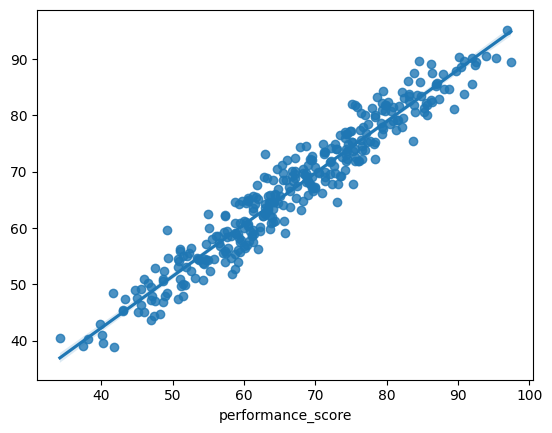

In [192]:
sns.regplot(x = y_test, y = y_pred)
plt.show()

In [193]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1142 entries, 0 to 1199
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   hours_studied       1142 non-null   float64
 1   attendance          1142 non-null   float64
 2   sleep_hours         1142 non-null   float64
 3   previous_scores     1142 non-null   float64
 4   tutoring_sessions   1142 non-null   float64
 5   physical_activity   1142 non-null   int64  
 6   gender              1142 non-null   int64  
 7   parental_education  1142 non-null   int64  
 8   internet_access     1142 non-null   int64  
 9   performance_score   1142 non-null   float64
dtypes: float64(6), int64(4)
memory usage: 98.1 KB


In [195]:
df

,hours_studied,attendance,sleep_hours,previous_scores,tutoring_sessions,physical_activity,gender,parental_education,internet_access,performance_score
0,4.4,87.9,6.2,81.2,7.0,6,1,2,1,80.1
1,9.6,51.2,6.7,87.7,6.0,1,1,2,1,89.1
2,7.6,51.1,4.5,40.3,7.0,2,0,1,1,65.5
3,6.4,66.2,5.8,88.3,0.0,3,0,1,1,66.1
4,2.4,74.4,8.4,67.8,4.0,2,1,0,1,61.3
...,...,...,...,...,...,...,...,...,...,...
1195,8.8,67.3,9.6,38.3,6.0,0,0,0,1,69.7
1196,9.8,57.7,7.3,32.6,0.0,4,1,1,0,57.3
1197,9.7,51.3,9.4,33.7,1.0,6,1,0,1,70.7
1198,7.7,82.3,5.9,88.4,2.0,4,1,1,1,83.2


In [197]:
hrs_studied = float(input("Enter the hours studied: "))
sleep_hours = float(input("Enter the sleep hours: "))
previous_scores = float(input("Enter the previous scores: "))
tutoring_sessions = float(input("Enter the tutoring sessions: "))
gender = int(input("Enter the gender (0/1): "))
parental_education = int(input("Enter the parental education (encoded): "))
attendance = float(input("Enter the attendance: "))
physical_activity = int(input("Enter the physical activity: "))
internet_access = int(input("Enter the internet access (0/1): "))

Enter the hours studied: 5.9
Enter the sleep hours: 7.7
Enter the previous scores: 90.8
Enter the tutoring sessions: 7.0
Enter the gender (0/1): 0
Enter the parental education (encoded): 2
Enter the attendance: 94.6
Enter the physical activity: 7
Enter the internet access (0/1): 1


In [203]:
# Construct a DataFrame with the user inputs matching the model's feature order
input_data = pd.DataFrame({
    'hours_studied': [hrs_studied],
    'attendance': [attendance],
    'sleep_hours': [sleep_hours],
    'previous_scores': [previous_scores],
    'tutoring_sessions': [tutoring_sessions],
    'physical_activity': [physical_activity],
    'gender': [gender],
    'parental_education': [parental_education],
    'internet_access': [internet_access]
})

# Make prediction
prediction = model.predict(input_data)
print(f"Predicted Performance Score: {prediction[0]:.2f}")

Predicted Performance Score: 87.50


In [205]:
comparition = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': np.round(y_pred,2),
    'Difference': np.round(y_test.values - y_pred, 2)
})
comparition

,Actual,Predicted,Difference
0,51.1,56.28,-5.18
1,45.2,45.00,0.20
2,79.5,84.27,-4.77
3,37.4,39.04,-1.64
4,72.2,74.23,-2.03
...,...,...,...
338,72.1,69.55,2.55
339,63.0,62.41,0.59
340,74.5,72.24,2.26
341,75.5,72.67,2.83
